In [3]:
import pandas as pd

df = pd.read_csv("Sample_ Superstore.csv", encoding="latin-1")

print(df.shape)
print(df.columns.tolist())
print(df.head(3))
print(df.dtypes)
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

(9994, 19)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Segment', 'Country', 'City', 'State', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
   Row ID        Order ID  Order Date   Ship Date     Ship Mode Customer ID  \
0       1  CA-2016-152156  11-08-2016  11-11-2016  Second Class    CG-12520   
1       2  CA-2016-152156  11-08-2016  11-11-2016  Second Class    CG-12520   
2       3  CA-2016-138688  06-12-2016   6/16/2016  Second Class    DV-13045   

     Segment        Country         City       State Region       Product ID  \
0   Consumer  United States    Henderson    Kentucky  South  FUR-BO-10001798   
1   Consumer  United States    Henderson    Kentucky  South  FUR-CH-10000454   
2  Corporate  United States  Los Angeles  California   West  OFF-LA-10000240   

          Category Sub-Category  \
0        Furniture    Bookcases   
1        Furniture       Chairs   
2  Office Supplies

In [5]:
# 1. Dates ko sahi format me convert karo (month-first)
for col in ["Order Date", "Ship Date"]:
    df[col] = pd.to_datetime(df[col].str.replace("-", "/"), format="%m/%d/%Y")

# 2. Check: ship date order date se pehle to nahi?
print("Ship before order:", (df["Ship Date"] < df["Order Date"]).sum())
print(df["Order Date"].min(), "to", df["Order Date"].max())

# 3. Kaam ke naye columns
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Profit Margin %"] = (df["Profit"] / df["Sales"] * 100).round(2)

# 4. Faltu columns hatao
df = df.drop(columns=["Row ID", "Country"])

print(df.shape)
print(df[["Sales", "Quantity", "Discount", "Profit", "Ship Days"]].describe().round(2))

Ship before order: 0
2014-01-03 00:00:00 to 2017-12-30 00:00:00
(9994, 21)
          Sales  Quantity  Discount   Profit  Ship Days
count   9994.00   9994.00   9994.00  9994.00    9994.00
mean     229.86      3.79      0.16    28.66       3.96
std      623.25      2.23      0.21   234.26       1.75
min        0.44      1.00      0.00 -6599.98       0.00
25%       17.28      2.00      0.00     1.73       3.00
50%       54.49      3.00      0.20     8.67       4.00
75%      209.94      5.00      0.20    29.36       5.00
max    22638.48     14.00      0.80  8399.98       7.00


In [7]:
print("Total Sales:", round(df["Sales"].sum(), 0))
print("Total Profit:", round(df["Profit"].sum(), 0))
print("Overall Margin %:", round(df["Profit"].sum() / df["Sales"].sum() * 100, 1))

print("\n--- Year-wise ---")
print(df.groupby("Year")[["Sales", "Profit"]].sum().round(0))

print("\n--- Category-wise ---")
print(df.groupby("Category")[["Sales", "Profit"]].sum().round(0))

print("\n--- Region-wise ---")
print(df.groupby("Region")[["Sales", "Profit"]].sum().round(0))

print("\n--- Sub-Category profit (best to worst) ---")
print(df.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False).round(0))

print("\n--- Discount vs Profit ---")
df["Discount Band"] = pd.cut(df["Discount"], [-0.01, 0, 0.2, 0.4, 1.0],
                             labels=["No discount", "Up to 20%", "20-40%", "Above 40%"])
print(df.groupby("Discount Band", observed=True)["Profit"].agg(["count", "sum", "mean"]).round(1))

Total Sales: 2297201.0
Total Profit: 286397.0
Overall Margin %: 12.5

--- Year-wise ---
         Sales   Profit
Year                   
2014  484247.0  49544.0
2015  470533.0  61619.0
2016  609206.0  81795.0
2017  733215.0  93439.0

--- Category-wise ---
                    Sales    Profit
Category                           
Furniture        742000.0   18451.0
Office Supplies  719047.0  122491.0
Technology       836154.0  145455.0

--- Region-wise ---
            Sales    Profit
Region                     
Central  501240.0   39706.0
East     678781.0   91523.0
South    391722.0   46749.0
West     725458.0  108418.0

--- Sub-Category profit (best to worst) ---
Sub-Category
Copiers        55618.0
Phones         44516.0
Accessories    41937.0
Paper          34054.0
Binders        30222.0
Chairs         26590.0
Storage        21279.0
Appliances     18138.0
Furnishings    13059.0
Envelopes       6964.0
Art             6528.0
Labels          5546.0
Machines        3385.0
Fasteners        95

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

# Tables: discount ka asar
tables = df[df["Sub-Category"] == "Tables"]
print(tables.groupby("Discount Band", observed=True)["Profit"].agg(["count", "sum"]).round(0))

# Central region me kaunse sub-category loss me hain
central = df[df["Region"] == "Central"]
print(central.groupby("Sub-Category")["Profit"].sum().sort_values().head(5).round(0))

# Region wise average discount
print(df.groupby("Region")["Discount"].mean().round(3))

               count      sum
Discount Band                
No discount       72  13276.0
Up to 20%         71   -304.0
20-40%           129 -19590.0
Above 40%         47 -11108.0
Sub-Category
Furnishings   -3906.0
Tables        -3560.0
Appliances    -2639.0
Bookcases     -1998.0
Machines      -1486.0
Name: Profit, dtype: float64
Region
Central    0.240
East       0.145
South      0.147
West       0.109
Name: Discount, dtype: float64


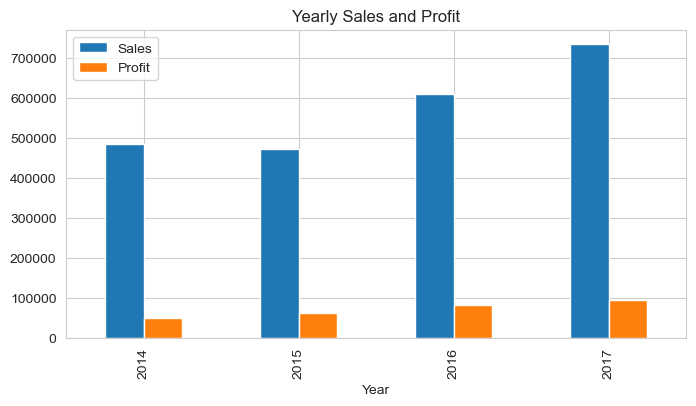

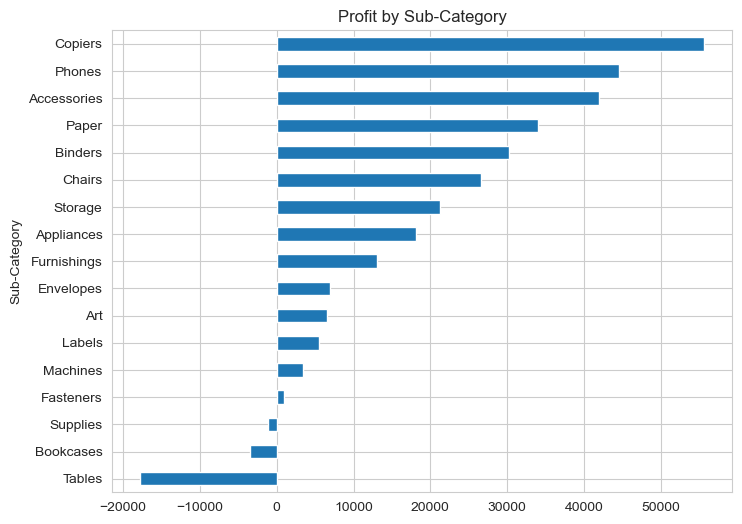

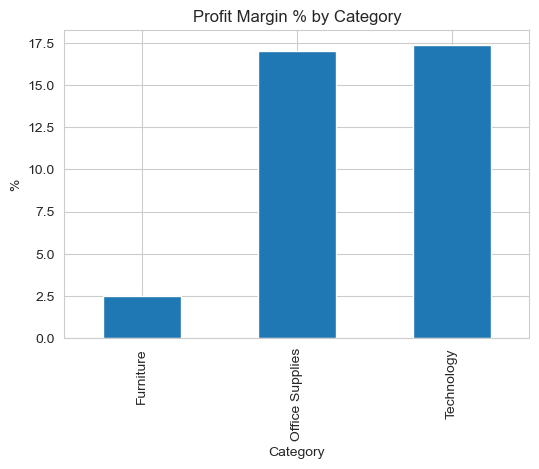

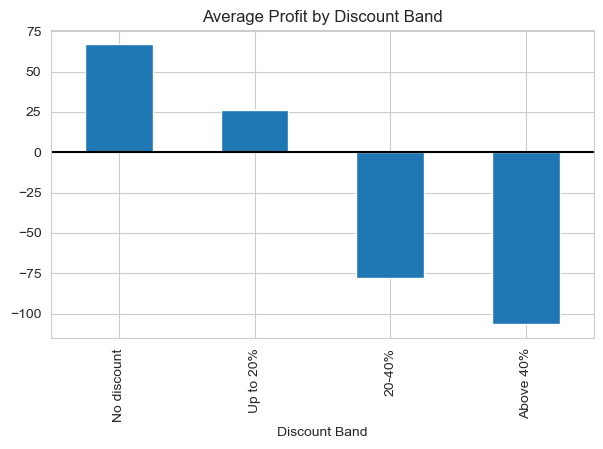

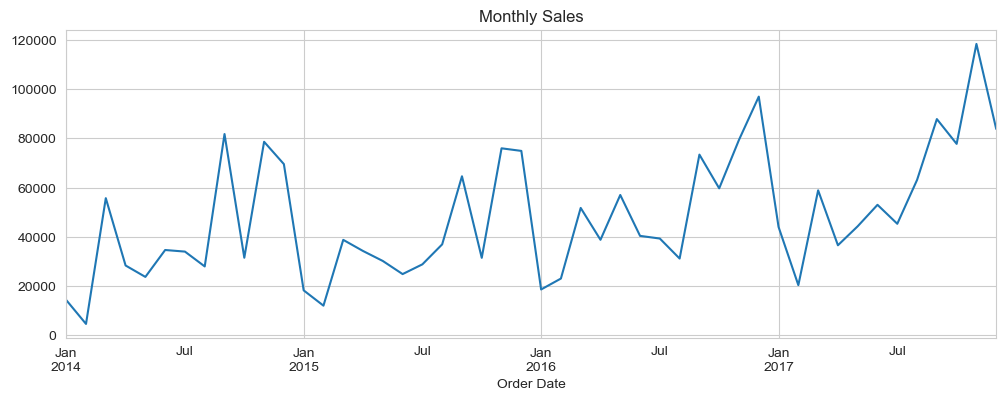

In [11]:
# Chart 1: Yearly sales vs profit
df.groupby("Year")[["Sales", "Profit"]].sum().plot(kind="bar", figsize=(8, 4))
plt.title("Yearly Sales and Profit"); plt.show()

# Chart 2: Sub-category profit
df.groupby("Sub-Category")["Profit"].sum().sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Profit by Sub-Category"); plt.show()

# Chart 3: Category profit margin
cat = df.groupby("Category")[["Sales", "Profit"]].sum()
(cat["Profit"] / cat["Sales"] * 100).plot(kind="bar", figsize=(6, 4))
plt.title("Profit Margin % by Category"); plt.ylabel("%"); plt.show()

# Chart 4: Discount vs average profit
df.groupby("Discount Band", observed=True)["Profit"].mean().plot(kind="bar", figsize=(7, 4))
plt.title("Average Profit by Discount Band"); plt.axhline(0, color="black"); plt.show()

# Chart 5: Monthly sales trend
df.set_index("Order Date")["Sales"].resample("M").sum().plot(figsize=(12, 4))
plt.title("Monthly Sales"); plt.show()